# Exotic Options by Monte Carlo: Asians, Barriers, Lookbacks and Variance Reduction

**Goal.** Price path-dependent options and, above all, price them *efficiently*: a desk
revalues thousands of trades every night, so cutting the Monte Carlo error by 30x at the
same cost is worth as much as a faster computer.

| Product | Payoff | Benchmark |
|---|---|---|
| Arithmetic Asian call | $(\bar S - K)^+$, average of 12 monthly fixings | geometric Asian (closed form) |
| Down-and-out call | $(S_T - K)^+$ if $S$ never touches $H$ | Reiner-Rubinstein + BGK correction |
| Floating lookback call | $S_T - \min_t S_t$ | Goldman-Sosin-Gatto |

**Variance reduction:** antithetic variates, control variates, and quasi-Monte Carlo
(scrambled Sobol points with a Brownian bridge).

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("exotics.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/04-exotic-options-monte-carlo")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from exotics import (gbm_paths, asian_call_mc, geometric_asian_call, barrier_call_mc, down_and_out_call,
                     down_and_out_call_discrete, lookback_call_mc, lookback_floating_call, bs_call)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f"
S0, K, T, r, q, sigma = 100.0, 100.0, 1.0, 0.04, 0.01, 0.25

## 1. What each payoff depends on

One simulated path shows the three path-dependent quantities: the running average
(Asian), the minimum (lookback), and whether the barrier is breached (barrier option).

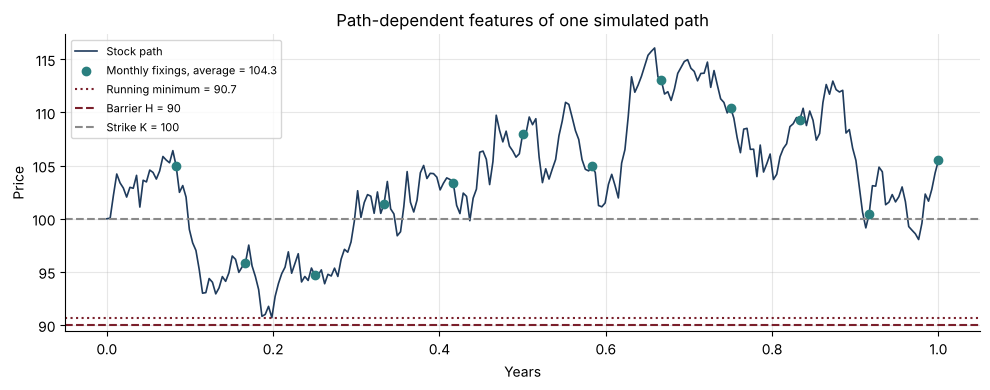

In [2]:
path = gbm_paths(S0, r, q, sigma, T, 252, 1, seed=11)[0]
t = np.linspace(0, T, 253)
fix_idx = np.arange(21, 253, 21)
plt.figure(figsize=(10, 4))
plt.plot(t, path, color=NAVY, lw=1.2, label="Stock path")
plt.scatter(t[fix_idx], path[fix_idx], color=TEAL, zorder=3, label=f"Monthly fixings, average = {path[fix_idx].mean():.1f}")
plt.axhline(path.min(), color=BORDEAUX, ls=":", label=f"Running minimum = {path.min():.1f}")
plt.axhline(90, color=BORDEAUX, ls="--", label="Barrier H = 90")
plt.axhline(K, color=GREY, ls="--", label="Strike K = 100")
plt.xlabel("Years"); plt.ylabel("Price"); plt.title("Path-dependent features of one simulated path")
plt.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.savefig("images/path.png", dpi=150); plt.show()

## 2. Asian option: four ways to reduce the error

- **Antithetic variates:** pair each draw $Z$ with $-Z$. Cheap, modest gain.
- **Control variate:** the geometric average $G$ is almost perfectly correlated with the
  arithmetic one and has an exact price. We estimate $X - c\,(G - \mathbb{E}[G])$ with the
  optimal $c = \mathrm{Cov}(X,G)/\mathrm{Var}(G)$, which removes most of the noise.
- **Quasi-Monte Carlo:** Sobol points fill the space more evenly than random draws. With a
  **Brownian bridge**, the best Sobol coordinate sets the terminal value, which drives most
  of the payoff. The error is measured over 16 independent scramblings.

The fair comparison is **efficiency** = 1 / (variance × time): how much accuracy each
second of computation buys.

In [3]:
n = 131_072
rows = []
for method in ["plain", "antithetic", "control", "sobol"]:
    t0 = time.perf_counter()
    p, se = asian_call_mc(S0, K, T, r, q, sigma, 12, n, seed=5, method=method)
    rows.append({"Method": method, "Price": p, "Std error": se, "Time (s)": time.perf_counter() - t0})
asian = pd.DataFrame(rows).set_index("Method")
asian["Efficiency vs plain"] = (asian.loc["plain", "Std error"]**2 * asian.loc["plain", "Time (s)"]) / (asian["Std error"]**2 * asian["Time (s)"])
print(f"Geometric Asian (exact) = {geometric_asian_call(S0, K, T, r, q, sigma, 12):.4f}   European call = {bs_call(S0, K, T, r, q, sigma):.4f}")
asian.round(4)

Geometric Asian (exact) = 6.4546   European call = 11.2356


,Price,Std error,Time (s),Efficiency vs plain
Method,,,,
plain,6.7874,0.0284,0.0908,1.0000
antithetic,6.7564,0.0214,0.0521,3.0725
control,6.7486,0.0010,0.0797,995.9937
sobol,6.7492,0.0005,0.1781,1422.6474


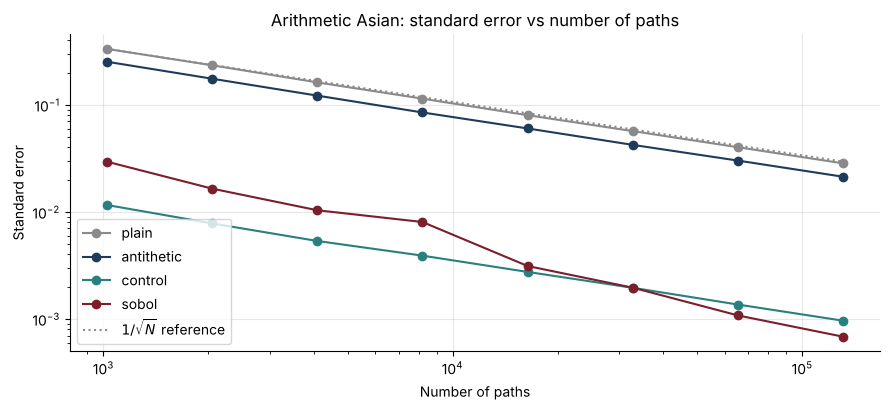

In [4]:
ns = 2 ** np.arange(10, 18)
errors = {m: [asian_call_mc(S0, K, T, r, q, sigma, 12, int(k), seed=3, method=m)[1] for k in ns]
          for m in ["plain", "antithetic", "control", "sobol"]}
plt.figure(figsize=(9, 4.2))
for (m, e), c in zip(errors.items(), [GREY, NAVY, TEAL, BORDEAUX]):
    plt.loglog(ns, e, marker="o", color=c, label=m)
plt.loglog(ns, errors["plain"][0] * np.sqrt(ns[0] / ns), color=GREY, ls=":", label=r"$1/\sqrt{N}$ reference")
plt.xlabel("Number of paths"); plt.ylabel("Standard error"); plt.legend()
plt.title("Arithmetic Asian: standard error vs number of paths")
plt.tight_layout(); plt.savefig("images/variance_reduction.png", dpi=150); plt.show()

**Reading the chart.** Plain and antithetic Monte Carlo decrease like $1/\sqrt{N}$. The
control variate keeps that slope but starts about 30 times lower, while Sobol with a
Brownian bridge converges **faster** than $1/\sqrt{N}$: its advantage grows with $N$.

## 3. Barrier option: the cost of discrete monitoring

Real barriers are observed at discrete dates (here weekly), while textbook formulas
assume continuous monitoring. A discrete barrier is breached less often, so the
down-and-out is worth more. **Broadie, Glasserman and Kou** showed that shifting the barrier
by $e^{-\beta\sigma\sqrt{\Delta t}}$ ($\beta \approx 0.5826$) makes the continuous formula
match the discrete product.

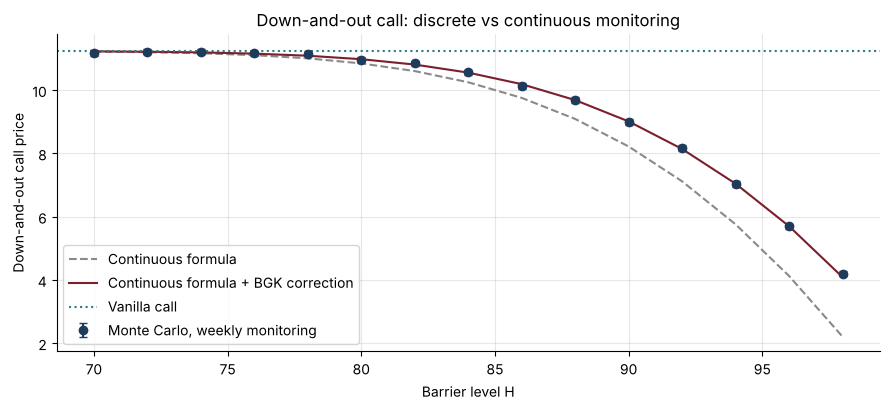

H = 90: out 9.0205 + in 2.2334 = 11.2539   vanilla 11.2539


In [5]:
barriers = np.arange(70, 100, 2.0)
mc_vals = [barrier_call_mc(S0, K, H, T, r, q, sigma, 52, 100_000, seed=int(H))["out"] for H in barriers]
plt.figure(figsize=(9, 4.2))
plt.errorbar(barriers, [m[0] for m in mc_vals], yerr=[1.96 * m[1] for m in mc_vals], fmt="o", color=NAVY,
             capsize=3, label="Monte Carlo, weekly monitoring")
plt.plot(barriers, down_and_out_call(S0, K, barriers, T, r, q, sigma), color=GREY, ls="--", label="Continuous formula")
plt.plot(barriers, down_and_out_call_discrete(S0, K, barriers, T, r, q, sigma, 52), color=BORDEAUX,
         label="Continuous formula + BGK correction")
plt.axhline(bs_call(S0, K, T, r, q, sigma), color=TEAL, ls=":", label="Vanilla call")
plt.xlabel("Barrier level H"); plt.ylabel("Down-and-out call price"); plt.legend()
plt.title("Down-and-out call: discrete vs continuous monitoring")
plt.tight_layout(); plt.savefig("images/barrier.png", dpi=150); plt.show()

res = barrier_call_mc(S0, K, 90, T, r, q, sigma, 52, 200_000)
print(f"H = 90: out {res['out'][0]:.4f} + in {res['in'][0]:.4f} = {res['out'][0] + res['in'][0]:.4f}   vanilla {res['vanilla'][0]:.4f}")

The in-out parity (down-and-in + down-and-out = vanilla) holds exactly on the same paths,
a useful check that the knock-out logic is right.

## 4. Lookback option: correcting the discrete minimum

The same idea applies to the running minimum: a minimum taken on a grid is too high.
Shifting it down by $e^{-\beta\sigma\sqrt{\Delta t}}$ removes most of the bias: from
weekly monitoring onwards, what remains is of the order of the Monte Carlo error.

In [6]:
steps = [12, 52, 252, 1000]
exact = lookback_floating_call(S0, T, r, q, sigma)
rows = []
for s in steps:
    raw, se = lookback_call_mc(S0, T, r, q, sigma, s, 200_000, seed=2, correct=False)
    corrected, _ = lookback_call_mc(S0, T, r, q, sigma, s, 200_000, seed=2, correct=True)
    rows.append({"Monitoring steps": s, "Raw MC": raw, "Corrected MC": corrected, "MC std error": se})
lb = pd.DataFrame(rows)
lb["Raw bias"] = lb["Raw MC"] - exact
lb["Corrected bias"] = lb["Corrected MC"] - exact
print(f"Continuous lookback (Goldman-Sosin-Gatto) = {exact:.4f}")
lb.round(4)

Continuous lookback (Goldman-Sosin-Gatto) = 19.4920


,Monitoring steps,Raw MC,Corrected MC,MC std error,Raw bias,Corrected bias
0,12,16.4415,19.8411,0.0254,-3.0505,0.3491
1,52,17.9641,19.5847,0.0249,-1.5279,0.0927
2,252,18.7673,19.5001,0.0246,-0.7247,0.0081
3,1000,19.1529,19.5200,0.0247,-0.3391,0.0279


## Conclusions
- The control variate and Sobol with a Brownian bridge cut the Asian error by 30x to 50x
  at the same number of paths, and the test suite checks that all methods agree.
- Discrete monitoring matters: on a weekly barrier at 90 the continuous formula
  misprices the option by almost 10%, and the BGK correction fixes it.
- **Next steps:** multilevel Monte Carlo, Greeks by pathwise and likelihood-ratio
  methods, and these payoffs under the Heston model (project 03).